# MSCM 684 1st Report

## Using Models examining Price in Airline Markets

### Gillen & Mantin (2009), Price Volatility in Airline Markets
Multiple Linear Regression Model explaining airfare volatility 

In [36]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

# 1. Import and sort the dataset
df = pd.read_csv(r"D:\Lorenzo Docs\School\MSCM 684\Project\airfare_30days_price.csv")
df = df.sort_values(["id", "time"]).copy()

df.head()

,id,time,origin,destination,distance,passengers,fare,carrier_lg,large_ms,fare_lg,carrier_low,lf_ms,fare_low
0,1,1,"ALBANY, NY","CHICAGO, IL",724,227.0,269.0,UA,43.08,277.0,AA,40.22,266.0
1,1,2,"ALBANY, NY","CHICAGO, IL",724,250.0,253.0,UA,42.34,273.0,AA,39.38,236.0
2,1,3,"ALBANY, NY","CHICAGO, IL",724,233.0,243.0,UA,46.04,252.0,AA,39.41,229.0
3,1,4,"ALBANY, NY","CHICAGO, IL",723,172.0,271.0,AA,46.41,257.0,AA,46.41,257.0
4,1,5,"ALBANY, NY","CHICAGO, IL",723,242.0,247.0,AA,45.39,232.0,AA,45.39,232.0


In [37]:
# 2. Calculate changes in average airfare
df["log_fare"] = np.log(df["fare"])

df["log_change"] = (
    df.groupby("id")["log_fare"].diff()
)

# 3. Calculate price volatility for each route
routes = df.groupby("id").agg(
    volatility=("log_change", "std"),
    distance=("distance", "mean"),
    passengers=("passengers", "mean"),
    largest_share=("large_ms", "mean"),
    lowest_fare_share=("lf_ms", "mean")
).dropna()

# 4. Transform variables
routes["distance_1000"] = routes["distance"] / 1000
routes["log_passengers"] = np.log1p(routes["passengers"])
routes["largest_share_10"] = routes["largest_share"] / 10
routes["lowest_fare_share_10"] = routes["lowest_fare_share"] / 10

In [40]:
# 5. Estimate multiple linear regression
model = smf.ols(
    "volatility ~ distance_1000 + log_passengers "
    "+ largest_share_10 + lowest_fare_share_10",
    data=routes
).fit(cov_type="HC3")

# 6. Display regression results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             volatility   R-squared:                       0.099
Model:                            OLS   Adj. R-squared:                  0.093
Method:                 Least Squares   F-statistic:                     18.88
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           1.26e-14
Time:                        17:37:10   Log-Likelihood:                 1239.7
No. Observations:                 599   AIC:                            -2469.
Df Residuals:                     594   BIC:                            -2447.
Df Model:                           4                                         
Covariance Type:                  HC3                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept                0.0957 

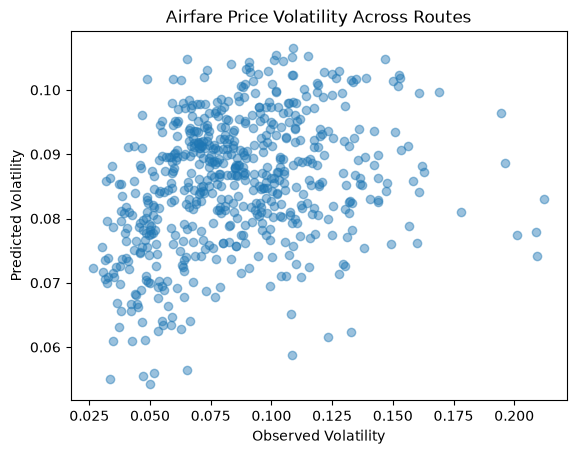

In [39]:
# 7. Compare observed and predicted volatility
routes["predicted_volatility"] = model.predict(routes)

plt.scatter(
    routes["volatility"],
    routes["predicted_volatility"],
    alpha=0.45
)

plt.xlabel("Observed Volatility")
plt.ylabel("Predicted Volatility")
plt.title("Airfare Price Volatility Across Routes")
plt.show()

### Mantin & Koo (2009) Dynamic Price Dispersion in Airline Markets
Multiple Linear Regression Model exploring how airfare price dispersion

In [41]:
# 1. Keep observations with valid positive fares
df_disp = df[df["fare"] > 0].copy()

In [42]:
# 2. Calculate price dispersion and route characteristics
routes_disp = df_disp.groupby("id").agg(
    avg_fare=("fare", "mean"),
    sd_fare=("fare", "std"),
    distance=("distance", "mean"),
    passengers=("passengers", "mean"),
    largest_share=("large_ms", "mean"),
    lowest_fare_share=("lf_ms", "mean")
)

# 3. Calculate coefficient of variation
routes_disp["dispersion_cv"] = (
    routes_disp["sd_fare"] / routes_disp["avg_fare"]
)

# 4. Transform variables
routes_disp["distance_1000"] = routes_disp["distance"] / 1000
routes_disp["log_passengers"] = np.log1p(routes_disp["passengers"])
routes_disp["largest_share_10"] = routes_disp["largest_share"] / 10
routes_disp["lowest_fare_share_10"] = routes_disp["lowest_fare_share"] / 10
routes_disp["avg_fare_100"] = routes_disp["avg_fare"] / 100

routes_disp = routes_disp.dropna()

In [45]:
# 5. Estimate multiple linear regression
dispersion_model = smf.ols(
    "dispersion_cv ~ distance_1000 + log_passengers "
    "+ largest_share_10 + lowest_fare_share_10 "
    "+ avg_fare_100",
    data=routes_disp
).fit(cov_type="HC3")

# 6. Display regression results
print(dispersion_model.summary())

                            OLS Regression Results                            
Dep. Variable:          dispersion_cv   R-squared:                       0.196
Model:                            OLS   Adj. R-squared:                  0.189
Method:                 Least Squares   F-statistic:                     26.66
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           2.42e-24
Time:                        17:38:17   Log-Likelihood:                 935.69
No. Observations:                 599   AIC:                            -1859.
Df Residuals:                     593   BIC:                            -1833.
Df Model:                           5                                         
Covariance Type:                  HC3                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               -0.0165 

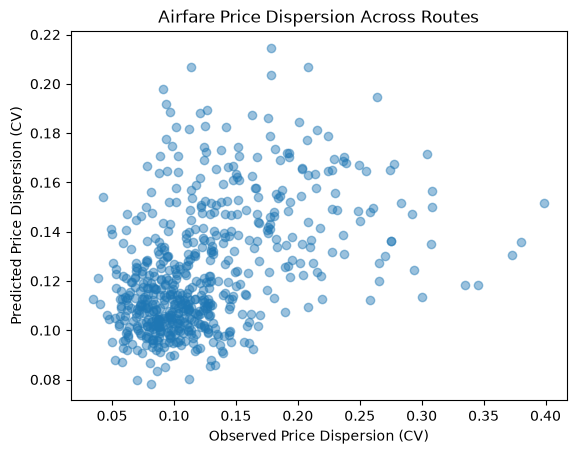

In [44]:
# 7. Compare observed and predicted dispersion
routes_disp["predicted_dispersion"] = dispersion_model.predict(routes_disp)

plt.scatter(
    routes_disp["dispersion_cv"],
    routes_disp["predicted_dispersion"],
    alpha=0.45
)

plt.xlabel("Observed Price Dispersion (CV)")
plt.ylabel("Predicted Price Dispersion (CV)")
plt.title("Airfare Price Dispersion Across Routes")
plt.show()

### Mantin & Koo (2010), Temporal Effects in Airfare Pricing
Comparing 2 Multiple Linear Regression Models to investigate whether airfares and price variation changes across observation periods

In [46]:
# 1. Prepare the dataset
df_time = df.sort_values(["id", "time"]).copy()

df_time["time_sq"] = df_time["time"] ** 2

In [47]:
# 2. Calculate airfare variation
df_time["route_mean_fare"] = (
    df_time.groupby("id")["fare"].transform("mean")
)

df_time["abs_deviation"] = (
    df_time["fare"] - df_time["route_mean_fare"]
).abs()

In [50]:
# 3. Estimate average airfare regression
price_model = smf.ols(
    "fare ~ time + time_sq + C(id)",
    data=df_time
).fit(
    cov_type="cluster",
    cov_kwds={"groups": df_time["id"]}
)

# 4. Estimate airfare variation regression
variation_model = smf.ols(
    "abs_deviation ~ time + time_sq + C(id)",
    data=df_time
).fit(
    cov_type="cluster",
    cov_kwds={"groups": df_time["id"]}
)

In [51]:
# 5. Display main regression results
for name, model in [
    ("Average Fare", price_model),
    ("Airfare Variation", variation_model)
]:
    print("\n", name)

    print(pd.DataFrame({
        "Coefficient": model.params[["time", "time_sq"]],
        "P-value": model.pvalues[["time", "time_sq"]]
    }))

    print("R-squared:", round(model.rsquared, 3))
    print(
        "Joint time effect p-value:",
        float(model.f_test("time = 0, time_sq = 0").pvalue)
    )


 Average Fare
         Coefficient       P-value
time        1.540955  1.020752e-22
time_sq    -0.068090  1.392384e-33
R-squared: 0.865
Joint time effect p-value: 1.2326745586410249e-29

 Airfare Variation
         Coefficient       P-value
time       -0.751171  1.496413e-19
time_sq     0.027154  4.216279e-24
R-squared: 0.502
Joint time effect p-value: 1.8318249837365464e-22


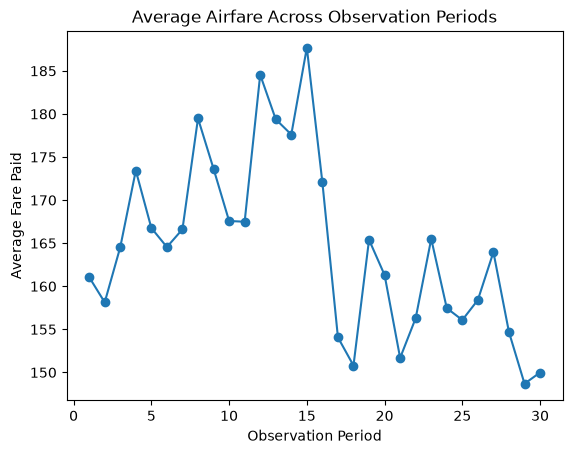

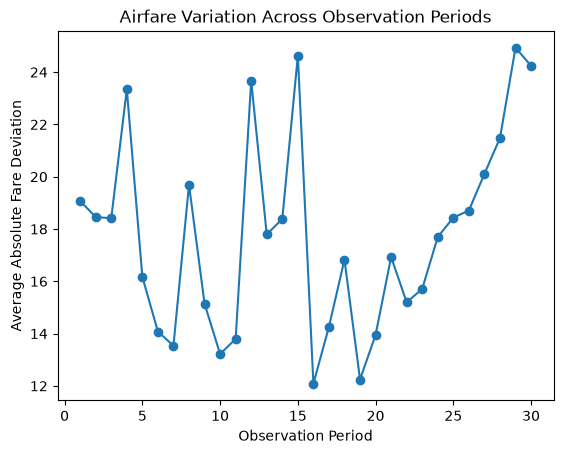

In [52]:
# 6. Visualize average airfare across periods
period_means = df_time.groupby("time")[
    ["fare", "abs_deviation"]
].mean()

period_means["fare"].plot(marker="o")

plt.xlabel("Observation Period")
plt.ylabel("Average Fare Paid")
plt.title("Average Airfare Across Observation Periods")
plt.show()

# 7. Visualize airfare variation across periods
period_means["abs_deviation"].plot(marker="o")

plt.xlabel("Observation Period")
plt.ylabel("Average Absolute Fare Deviation")
plt.title("Airfare Variation Across Observation Periods")
plt.show()